## **Load the Dataset**

In [104]:
from google.colab import files

uploaded = files.upload()

Saving telco_customer_churn.csv to telco_customer_churn.csv


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Dataset
df = pd.read_csv("telco_customer_churn.csv")

# Show all the columns
pd.set_option('display.max_columns', None)
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **Exploratory Data Analysis (EDA)**

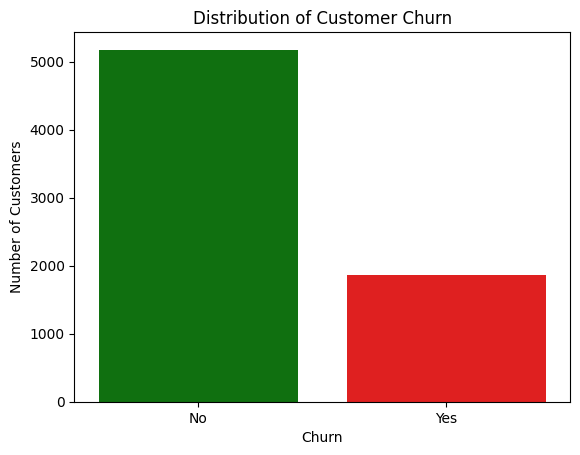

In [106]:
import seaborn as sns

# How many customers churned compared to those who stayed ?

sns.countplot(data=df, x="Churn", hue="Churn", palette={"No": "green", "Yes": "red"}, legend=False)
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

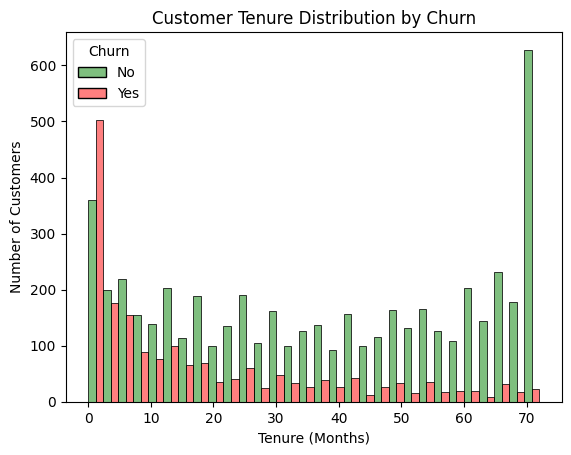

In [107]:
# How does customer tenure differ between customers who churn and those who stay ?

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, palette={"No": "green", "Yes": "red"}, alpha=0.5, multiple="dodge")
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

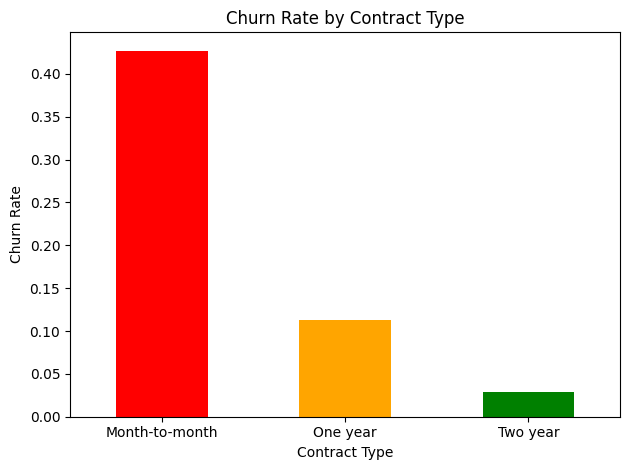

In [108]:
# Which contract types have the highest churn rate ?

churn_rate = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean()
)

churn_rate.plot(kind="bar", color=["red", "orange", "green"])
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

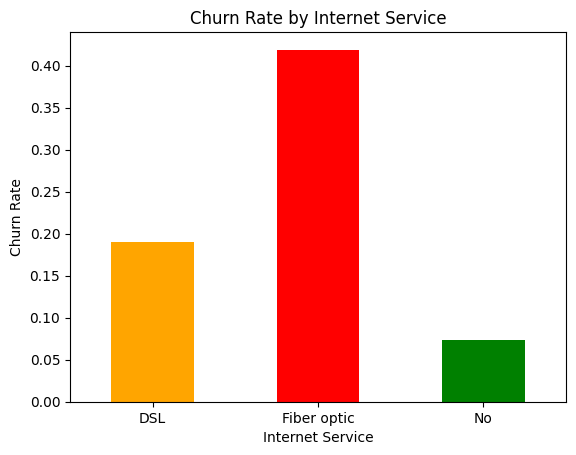

In [109]:
# Which internet service type have the highest churn rate ?

churn_rate = df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").mean()
)

churn_rate.plot(kind="bar", color=["orange", "red", "green"])
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate")
plt.xticks(rotation=0)
plt.show()

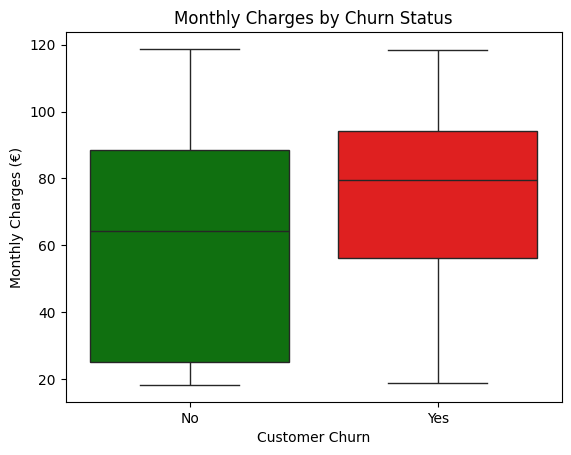

In [110]:
# Do monthly charges differ between customers who churn and those who stay ?

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette={"No": "green", "Yes": "red"}, legend=False)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges (€)")
plt.show()

## **Data Preprocessing and Feature Engineering**

In [111]:
# No useful information
df = df.drop('customerID', axis=1)

# Features
X = df.iloc[:, :-1]

# Targets
y = df["Churn"].map({"No": 0, "Yes": 1})

In [112]:
# Identify categorical features stored as strings that need to be encoded
print(X.select_dtypes(include="object").columns)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'TotalCharges'],
      dtype='object')


In [113]:
# Convert TotalCharges to numeric
X["TotalCharges"] = pd.to_numeric(X["TotalCharges"].astype(str).str.strip(), errors="coerce")

# Identify missing values
print(X.isna().sum())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
dtype: int64


In [114]:
# Fill the missing values with 0
X["TotalCharges"] = X["TotalCharges"].fillna(0)

print(X.isna().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64


In [115]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = [
    "gender", "Partner", "Dependents",
    "PhoneService", "PaperlessBilling",
    "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaymentMethod"
]

numerical_features = [
    "SeniorCitizen", "tenure",
    "MonthlyCharges", "TotalCharges"
]


preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numerical_features)
])


# Split the dataset into training (60%), validation (20%), and test (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size = 0.5, random_state=42)

# Apply one-hot encoding to convert categorical features into numerical
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

print("Shape of Train Features: ", X_train.shape)
print("Shape of Train Targets: ", y_train.shape)
print("Shape of CV and Test Features: ", X_val.shape)
print("Shape of CV and Test Targets: ", y_val.shape)

Shape of Train Features:  (4225, 45)
Shape of Train Targets:  (4225,)
Shape of CV and Test Features:  (1409, 45)
Shape of CV and Test Targets:  (1409,)


## **Deep Learning Model (Tensorflow)**


In [116]:
import tensorflow as tf
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Dense
from keras.activations import relu, sigmoid
from keras.losses import BinaryCrossentropy

# Define a neural network for binary churn classification
model = Sequential([
    tf.keras.Input(shape=(45, )),
    Dense(25, activation="relu", kernel_regularizer=tf.keras.regularizers.L2(0.001)),
    Dense(15, activation="relu", kernel_regularizer=tf.keras.regularizers.L2(0.001)),
    Dense(1, activation="sigmoid")
])

# Configure the model with Adam, binary cross-entropy loss, and accuracy as the evaluation metric
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss=BinaryCrossentropy,
              metrics=["accuracy"])

# Train the model and monitor its performance on the validation set
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs = 150)


Epoch 1/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3141 - loss: 0.8238 - val_accuracy: 0.4209 - val_loss: 0.7712
Epoch 2/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5896 - loss: 0.7314 - val_accuracy: 0.6884 - val_loss: 0.6988
Epoch 3/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7325 - loss: 0.6660 - val_accuracy: 0.7417 - val_loss: 0.6393
Epoch 4/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7375 - loss: 0.6166 - val_accuracy: 0.7374 - val_loss: 0.5954
Epoch 5/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7385 - loss: 0.5810 - val_accuracy: 0.7374 - val_loss: 0.5624
Epoch 6/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7432 - loss: 0.5553 - val_accuracy: 0.7417 - val_loss: 0.5374
Epoch 7/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7555 - loss: 0.5366 - val_accuracy: 0.7622 - val_loss: 0.5187
Epoch 8/150
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7683 - loss: 0.5225 - val_accu

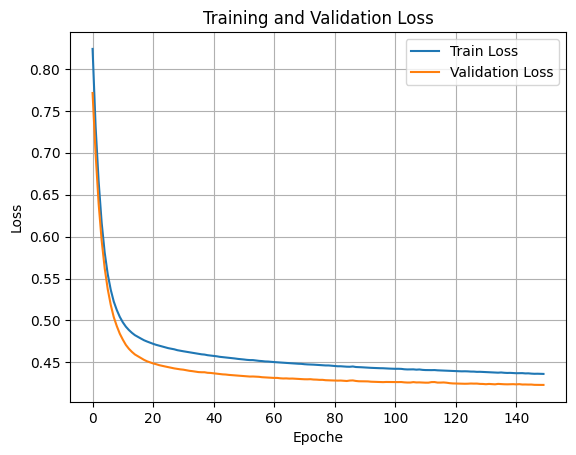

In [117]:
# Plot training and validation loss to monitor learning progress and identify potential overfitting
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoche")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Validation Set Accuracy: 0.8168914123491838
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1031
           1       0.69      0.57      0.63       378

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



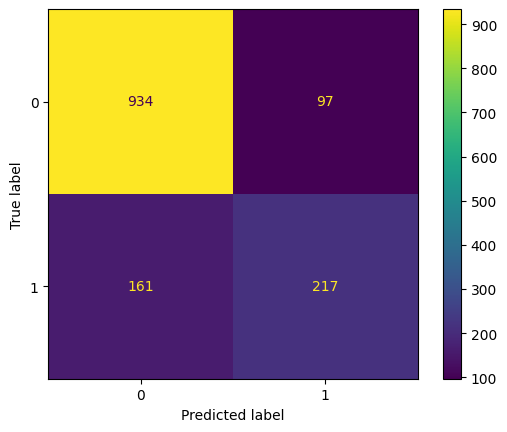

In [118]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Generate churn probabilities on the validation set
y_pred_prob = model.predict(X_val)

# Convert probabilities into binary class predictions using a threshold of 0.5
y_pred_dl = (y_pred_prob >= 0.5).astype(int).ravel()

# Evaluate model performance using accuracy, precision, recall, and F1-score
print("Validation Set Accuracy:", accuracy_score(y_val, y_pred_dl))
print(classification_report(y_val, y_pred_dl))

# Visualize correct and incorrect predictions with a confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_dl)
plt.show()



## **Random Forest Classifier**

In [119]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Initialize the Random Forest classifier
rf = RandomForestClassifier(random_state=42)

# Define the hyperparameter search space
param_grid = [{
    "bootstrap": [True, False],
    "n_estimators": [10,50,100,500],
    "max_depth": [2, 10, 30, 50, 100, 200],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
    "class_weight": [None, "balanced", "balanced_subsample"]
}]

# Search for the best hyperparameter combination using 5-fold cross-validation
random_grid_search = RandomizedSearchCV(rf, param_grid, cv=5, scoring="accuracy", n_iter=100, n_jobs=2, verbose=2)

# Fit and evaluate candidate models on the training data
random_grid_search.fit(X_train, y_train)

# Retrieve the best-performing estimator and its cross-validation score
rf = random_grid_search.best_estimator_

print(random_grid_search.best_score_)
print(random_grid_search.best_params_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
0.7952662721893492
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 30, 'class_weight': None, 'bootstrap': True}


Random Grid Search Validation Set Accuracy: 0.8133427963094393
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1031
           1       0.69      0.54      0.61       378

    accuracy                           0.81      1409
   macro avg       0.77      0.73      0.74      1409
weighted avg       0.80      0.81      0.81      1409



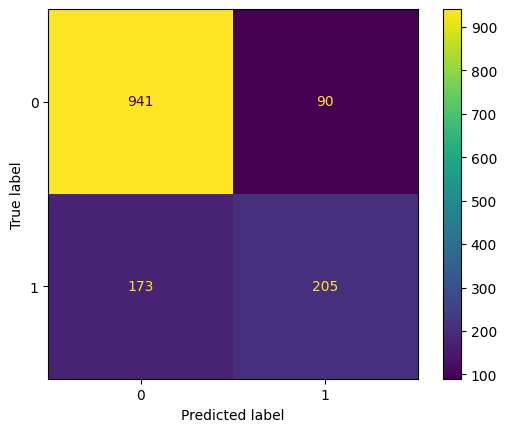

In [120]:
# Generate predictions on the validation set using the best Random Forest model
y_pred_rf = rf.predict(X_val)

# Evaluate model performance using accuracy, precision, recall, and F1-score
print("Random Grid Search Validation Set Accuracy:", accuracy_score(y_val, y_pred_rf))
print(classification_report(y_val, y_pred_rf))

# Visualize correct and incorrect predictions with a confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_rf)
plt.show()

## **XGBoost Classifier**

In [121]:
import xgboost as xgb

# Define the hyperparameter search space for XGBoost
param_grid = [{
    "n_estimators": [10,50,100,500],
    "learning_rate": [0.001, 0.01, 0.1, 0.2],
    "max_depth": [2, 10, 30, 50, 100, 200],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1, 10, 100],
    "reg_lambda": [0.001, 0.01, 0.1]
}]

# Initialize the XGBoost classifier
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric="logloss")

# Search for the best hyperparameter combination using 5-fold cross-validation
grid_search = RandomizedSearchCV(xgb_model, param_grid, cv=5, scoring='accuracy', n_iter=100, n_jobs=2, verbose=2)

# Fit and evaluate candidate models using cross-validation
grid_search.fit(X_train, y_train)

# Retrieve the best-performing XGBoost model and its parameters
best_xgb = grid_search.best_estimator_

print(grid_search.best_score_)
print(grid_search.best_params_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
0.7955029585798817
{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


Cross Validation Set Accuracy: 0.8112136266855926
              precision    recall  f1-score   support

           0       0.84      0.91      0.88      1031
           1       0.69      0.54      0.61       378

    accuracy                           0.81      1409
   macro avg       0.77      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



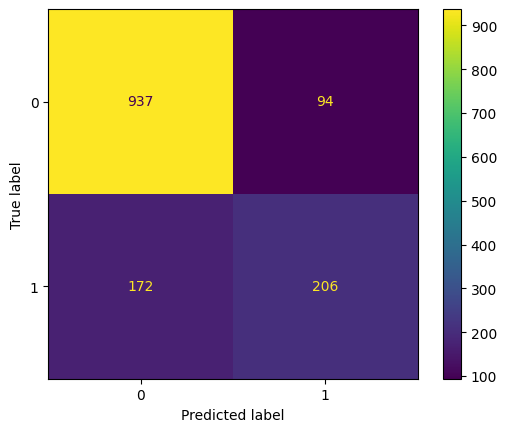

In [122]:
# Generate predictions on the validation set using the best XGBoost model
y_pred_xgb = best_xgb.predict(X_val)

# Evaluate model performance using accuracy, precision, recall, and F1-score
print("Cross Validation Set Accuracy:", accuracy_score(y_val, y_pred_xgb))
print(classification_report(y_val, y_pred_xgb))

# Visualize correct and incorrect predictions with a confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_xgb)
plt.show()

## **Model Comparison and Final Evaluation**

In [123]:

# Generate predictions on the test set using the trained models


# Deep Learning: Convert predicted probabilities into binary class labels
y_pred_prob = model.predict(X_test)
y_pred_dl = (y_pred_prob >= 0.5).astype(int).ravel()

# Random Forest: Predict class labels using the best estimator
y_pred_rf = rf.predict(X_test)

# XGBoost: Predict class labels using the best estimator
y_pred_xgb = best_xgb.predict(X_test)

# Compare the test accuracy of all three models
print("Deep Learning Accuracy on Test Set: ", accuracy_score(y_test, y_pred_dl))
print("Random Forest Accuracy on Test Set: ", accuracy_score(y_test, y_pred_rf))
print("XGB Boost Accuracy on Test Set: ", accuracy_score(y_test, y_pred_xgb))



45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Deep Learning Accuracy on Test Set:  0.8147622427253371
Random Forest Accuracy on Test Set:  0.8147622427253371
XGB Boost Accuracy on Test Set:  0.8161816891412349



==================== Deep Learning ====================
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1038
           1       0.67      0.58      0.62       371

    accuracy                           0.81      1409
   macro avg       0.76      0.74      0.75      1409
weighted avg       0.81      0.81      0.81      1409


==================== Random Forest ====================
              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1038
           1       0.71      0.51      0.59       371

    accuracy                           0.81      1409
   macro avg       0.77      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409


==================== XGBoost ====================
              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1038
           1       0.70      0.53      0.60       371

    accuracy     

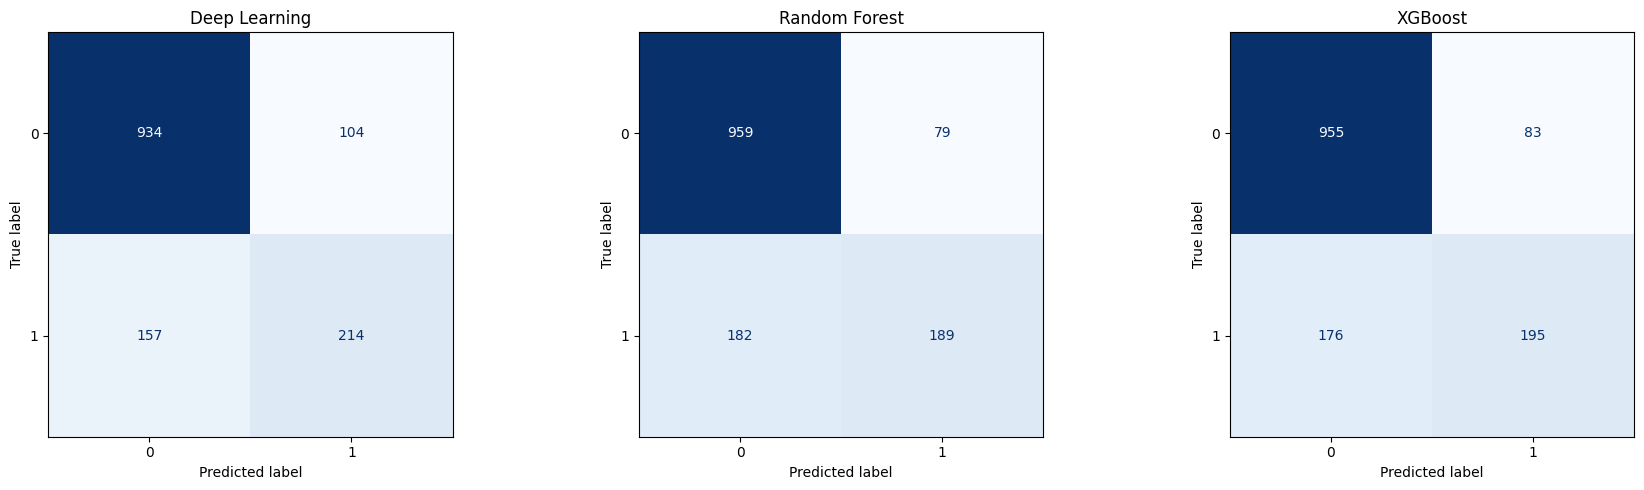

In [124]:
# Compare all three models using classification reports and side-by-side confusion matrices on the test set

models = {"Deep Learning": y_pred_dl, "Random Forest": y_pred_rf, "XGBoost": y_pred_xgb}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, models.items()):
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


## **Conclusion**

The three models achieved similar overall accuracy, ranging from 81% to 82%.

- **Deep Learning** achieved the highest recall (0.58) and F1-score (0.62) for the churn class.

- **Random Forest** achieved the highest precision (0.71) for the churn class.

- **XGBoost** achieved the highest overall accuracy (82%).

Overall, Deep Learning performed best at identifying customers who churned, while XGBoost achieved the highest accuracy. However, all three models missed a considerable proportion of actual churn cases, leaving room for further improvement.